In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [22]:
import sys
import importlib
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Audio, display

REPO_URL = "https://github.com/gauthamburg/Carnatic-Musical-Phrase-Generation.git"
REPO_DIR = "/content/Carnatic-Musical-Phrase-Generation"

MODEL_NAME = "diffusion"
MODEL_CONFIGS = {
    "diffusion": {
        "timesteps": 500,
        "channels": 64,
        "time_dim": 128
    },

    "vae": {
        "latent_dim": 2
    },

    "transformer_vae": {
        "d_model": 64,
        "nhead": 4,
        "num_layers": 2,
        "latent_dim": 2
    }
}

MODEL_PARAMS = MODEL_CONFIGS[MODEL_NAME]

DATA_DIR = "/content/drive/MyDrive/carnatic/Carnatic"
RAGA = "Rāgamālika"
PHRASE = "ggnpgr"

SEQ_LEN = 128
BATCH_SIZE = 16
EPOCHS = 100
LEARNING_RATE = 0.001

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUTPUT_DIR = f"/content/drive/MyDrive/carnatic_{MODEL_NAME}/{RAGA}/{PHRASE}"

In [23]:
!rm -rf {REPO_DIR}
!git clone -q {REPO_URL} {REPO_DIR}

In [24]:
for name in ("model", "train", "generate"):
    sys.modules.pop(name, None)

sys.path.insert(0, REPO_DIR)
sys.path.insert(0, f"{REPO_DIR}/models/{MODEL_NAME}")

from preprocessing import load_training_data
train = importlib.import_module("train")
generate = importlib.import_module("generate")

In [25]:
dataset, dataloader, contour_mean, contour_std = load_training_data(
    DATA_DIR=DATA_DIR,
    raga=RAGA,
    phrase=PHRASE,
    batch_size=BATCH_SIZE,
    seq_len=SEQ_LEN
)


Extraction complete
Selected raga: Rāgamālika
Selected phrase: ggnpgr
Matching performances: 4
Tonic handling: read separately from each performance's .ctonic.txt
Extracted phrase instances: 11
Skipped instances: 0
Contour array shape: (11, 128)

Dataset prepared
Dataset size: 11
Contour shape: torch.Size([1, 128])
Batch size: 16
Normalization mean: 1173.61
Normalization std: 258.62


Training started
Device: cuda
Training instances: 11
Epoch 10/100 | Loss: 0.3531
Epoch 20/100 | Loss: 0.3401
Epoch 30/100 | Loss: 0.2018
Epoch 40/100 | Loss: 0.4687
Epoch 50/100 | Loss: 0.3116
Epoch 60/100 | Loss: 0.3028
Epoch 70/100 | Loss: 0.2402
Epoch 80/100 | Loss: 0.1341
Epoch 90/100 | Loss: 0.2713
Epoch 100/100 | Loss: 0.0911


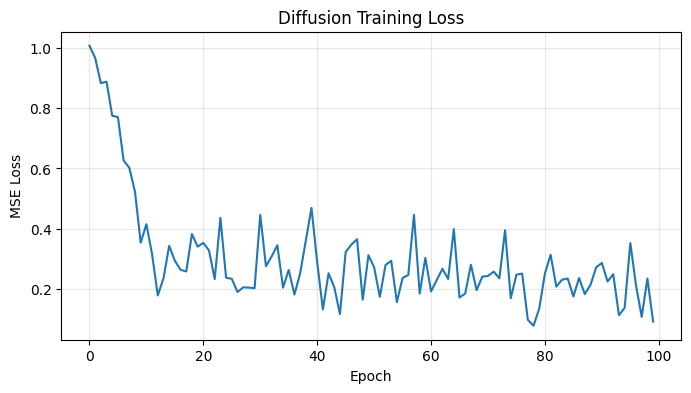

Training completed!
Checkpoint saved: /content/drive/MyDrive/carnatic_diffusion/Rāgamālika/ggnpgr/diffusion_checkpoint.pt


In [26]:
checkpoint_path, loss_history = train.train_model(
    dataloader=dataloader,
    dataset=dataset,
    contour_mean=contour_mean,
    contour_std=contour_std,
    output_dir=OUTPUT_DIR,
    device=DEVICE,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    **MODEL_PARAMS
)

In [27]:
generated_phrase = generate.generate_phrase(
    checkpoint_path=checkpoint_path,
    device=DEVICE,
    #seq_len=SEQ_LEN
)

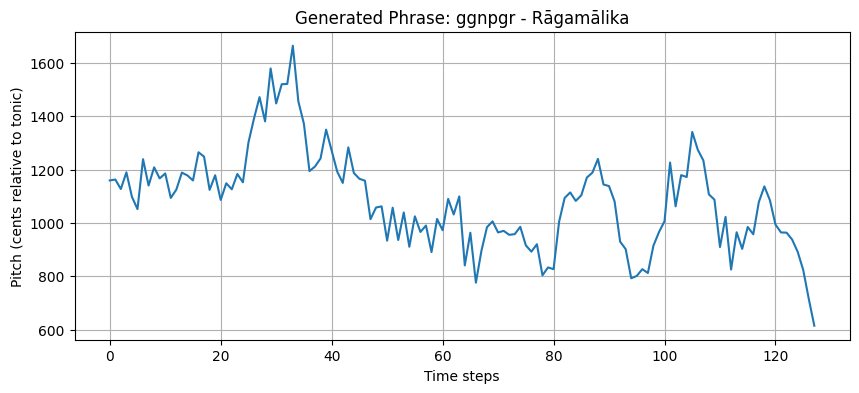

In [28]:
plt.figure(figsize=(10, 4))
plt.plot(generated_phrase)
plt.xlabel("Time steps")
plt.ylabel("Pitch (cents relative to tonic)")
plt.title(f"Generated Phrase: {PHRASE} - {RAGA}")
plt.grid(True)
plt.show()

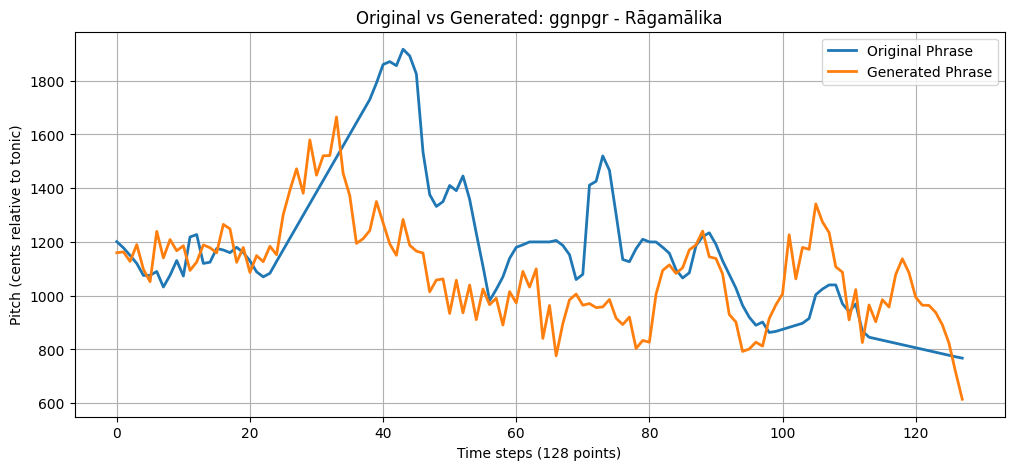

In [29]:
original_phrase = dataset[0].squeeze().numpy() * contour_std + contour_mean

plt.figure(figsize=(12, 5))
plt.plot(original_phrase, label="Original Phrase", linewidth=2)
plt.plot(generated_phrase, label="Generated Phrase", linewidth=2)
plt.xlabel(f"Time steps ({SEQ_LEN} points)")
plt.ylabel("Pitch (cents relative to tonic)")
plt.title(f"Original vs Generated: {PHRASE} - {RAGA}")
plt.legend()
plt.grid(True)
plt.show()

In [30]:
def sonify_phrase(pitch_contour, tonic_hz, duration=3.0, sample_rate=22050):
    frequencies = tonic_hz * (2 ** (pitch_contour / 1200))
    num_samples = int(duration * sample_rate)

    times = np.linspace(0, duration, len(frequencies))
    audio_times = np.linspace(0, duration, num_samples)
    interpolated_freq = np.interp(audio_times, times, frequencies)

    phase = 2 * np.pi * np.cumsum(interpolated_freq) / sample_rate
    audio = np.sin(phase)

    fade_length = int(0.05 * sample_rate)
    audio[:fade_length] *= np.linspace(0, 1, fade_length)
    audio[-fade_length:] *= np.linspace(1, 0, fade_length)

    return Audio(audio, rate=sample_rate)

In [31]:
import os
from preprocessing import get_tonic, get_performance_ragas

playback_tonic_hz = None
tonic_source_performance = None

for root, dirs, files in os.walk(DATA_DIR):
    if not any(name.endswith(".mphrases-manual.txt") for name in files):
        continue

    performance_ragas = get_performance_ragas(root)
    if not any(
        name.strip().casefold() == RAGA.strip().casefold()
        for name in performance_ragas
    ):
        continue

    candidate_tonic = get_tonic(root)
    if candidate_tonic is not None and candidate_tonic > 0:
        playback_tonic_hz = candidate_tonic
        tonic_source_performance = root
        break

if playback_tonic_hz is None:
    raise ValueError(
        f"Could not find a valid .ctonic.txt tonic for raga '{RAGA}'."
    )

print(f"Playback tonic: {playback_tonic_hz:.2f} Hz")
print(f"Tonic taken from: {tonic_source_performance}")

# Play the original and generated contours at the same tonic.
print("Original phrase:")
display(sonify_phrase(original_phrase, playback_tonic_hz))

print("Generated phrase:")
display(sonify_phrase(generated_phrase, playback_tonic_hz))


Playback tonic: 130.06 Hz
Tonic taken from: /content/drive/MyDrive/carnatic/Carnatic/87
Original phrase:


Generated phrase:
